In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'tensorflow', 'keras', 'protobuf', 'ml-dtypes']
imports = {'pillow': 'PIL', 'protobuf': 'google.protobuf', 'ml-dtypes': 'ml_dtypes'}
pinned = {}
fallbacks = {'tensorflow': 'tensorflow==2.21.0', 'keras': 'keras==3.14.0', 'protobuf': 'protobuf==7.34.1', 'ml-dtypes': 'ml-dtypes==0.5.4'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'tensorflow' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'tensorflow' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, _, _, match) in pinned.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "8a5255b0fce49fc730baae6ea6ecc601d45bb16b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/8a5255b0fce49fc730baae6ea6ecc601d45bb16b/d2l"
for name in ('__init__.py', 'tensorflow.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Object Detection and Bounding Boxes


In earlier sections (e.g., that section to that section),
we introduced various models for image classification.
In image classification tasks,
we assume that there is only *one*
major object
in the image and we only focus on how to 
recognize its category.
However, there are often *multiple* objects
in the image of interest.
We not only want to know their categories, but also their specific positions in the image.
In computer vision, we refer to such tasks as *object detection* (or *object recognition*).

Object detection has been
widely applied in many fields.
For example, self-driving needs to plan 
traveling routes
by detecting the positions
of vehicles, pedestrians, roads, and obstacles in the captured video images.
Besides,
robots may use this technique
to detect and localize objects of interest
throughout its navigation of an environment.
Moreover,
security systems
may need to detect abnormal objects, such as intruders or bombs.

In the next few sections, we will introduce 
several deep learning methods for object detection.
We will begin with an introduction
to *positions* (or *locations*) of objects.

In [ ]:
import math
import numpy as np
import tensorflow as tf
from d2l import tensorflow as d2l

We will load the sample image to be used in this section. We can see that there is a dog on the left side of the image and a cat on the right.
They are the two major objects in this image.

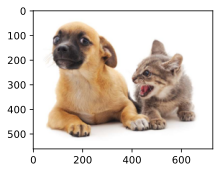

In [2]:
d2l.set_figsize()
img = d2l.plt.imread('../img/catdog.jpg')
d2l.plt.imshow(img);

## Bounding Boxes


In object detection,
we usually use a *bounding box* to describe the spatial location of an object.
The bounding box is rectangular, which is determined by the $x$ and $y$ coordinates of the upper-left corner of the rectangle and the such coordinates of the lower-right corner. 
Another commonly used bounding box representation is the $(x, y)$-axis
coordinates of the bounding box center, and the width and height of the box.

Here we define functions to convert between these two
representations:
`box_corner_to_center` converts from the two-corner
representation to the center-width-height representation,
and `box_center_to_corner` vice versa.
The input argument `boxes` should be a two-dimensional tensor of
shape ($n$, 4), where $n$ is the number of bounding boxes.

In [3]:

def box_corner_to_center(boxes):
    """Convert from (upper-left, lower-right) to (center, width, height)."""
    x1, y1, x2, y2 = boxes[:, 0], boxes[:, 1], boxes[:, 2], boxes[:, 3]
    cx = (x1 + x2) / 2
    cy = (y1 + y2) / 2
    w = x2 - x1
    h = y2 - y1
    boxes = d2l.stack((cx, cy, w, h), axis=-1)
    return boxes


def box_center_to_corner(boxes):
    """Convert from (center, width, height) to (upper-left, lower-right)."""
    cx, cy, w, h = boxes[:, 0], boxes[:, 1], boxes[:, 2], boxes[:, 3]
    x1 = cx - 0.5 * w
    y1 = cy - 0.5 * h
    x2 = cx + 0.5 * w
    y2 = cy + 0.5 * h
    boxes = d2l.stack((x1, y1, x2, y2), axis=-1)
    return boxes

We will define the bounding boxes of the dog and the cat in the image based
on the coordinate information.
The origin of the coordinates in the image
is the upper-left corner of the image, and to the right and down are the
positive directions of the $x$ and $y$ axes, respectively.

In [4]:
# Here `bbox` is the abbreviation for bounding box
dog_bbox, cat_bbox = [60.0, 45.0, 378.0, 516.0], [400.0, 112.0, 655.0, 493.0]

We can verify the correctness of the two
bounding box conversion functions by converting twice.

In [5]:
boxes = d2l.tensor((dog_bbox, cat_bbox))
box_center_to_corner(box_corner_to_center(boxes)) == boxes

<tf.Tensor: shape=(2, 4), dtype=bool, numpy=
array([[ True,  True,  True,  True],
       [ True,  True,  True,  True]])>

Let's draw the bounding boxes in the image to check if they are accurate.
Before drawing, we will define a helper function `bbox_to_rect`. It represents the bounding box in the bounding box format of the  `matplotlib` package.

In [6]:

def bbox_to_rect(bbox, color):
    """Convert bounding box to matplotlib format."""
    # Convert the bounding box (upper-left x, upper-left y, lower-right x,
    # lower-right y) format to the matplotlib format: ((upper-left x,
    # upper-left y), width, height)
    return d2l.plt.Rectangle(
        xy=(bbox[0], bbox[1]), width=bbox[2]-bbox[0], height=bbox[3]-bbox[1],
        fill=False, edgecolor=color, linewidth=2)

After adding the bounding boxes on the image,
we can see that the main outline of the two objects is basically inside the two boxes.

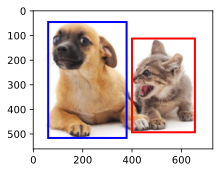

In [7]:
fig = d2l.plt.imshow(img)
fig.axes.add_patch(bbox_to_rect(dog_bbox, 'blue'))
fig.axes.add_patch(bbox_to_rect(cat_bbox, 'red'));

## Summary

* Object detection not only recognizes all the objects of interest in the image, but also their positions. The position is generally represented by a rectangular bounding box.
* We can convert between two commonly used bounding box representations.

## Exercises

1. Find another image and try to label a bounding box that contains the object. Compare labeling bounding boxes and categories: which usually takes longer?
1. Why is the innermost dimension of the input argument `boxes` of `box_corner_to_center` and `box_center_to_corner` always 4?
1. Data augmentation for object detection must transform the boxes together with the image. Let the image have width $W$ and height $H$.
    1. Show that flipping the image left to right maps the box $(x_1, y_1, x_2, y_2)$ to $(W - x_2, y_1, W - x_1, y_2)$, and that rotating it by 90 degrees counterclockwise maps the box to $(y_1, W - x_2, y_2, W - x_1)$ in an image of width $H$ and height $W$. Why do the corners have to be reordered?
    1. Implement both maps for a tensor `boxes` of shape ($n$, 4). Apply them to `dog_bbox` and `cat_bbox`, and draw the results with `bbox_to_rect` on the flipped image `img[:, ::-1]` and on the rotated image `img.transpose(1, 0, 2)[::-1]` to check them.
1. Suppose that an annotator places each of the four corner coordinates $x_1, y_1, x_2, y_2$ with an independent error of standard deviation $\sigma$ pixels. Write `box_corner_to_center` as a $4 \times 4$ matrix acting on $(x_1, y_1, x_2, y_2)^\top$, and use it to show that the center coordinates have standard deviation $\sigma/\sqrt{2}$, the width and height have standard deviation $\sqrt{2}\sigma$, and the center is uncorrelated with the width and height. For the cat box and $\sigma = 5$ pixels, estimate to first order the relative standard deviation of the box area.
1. An axis-aligned box describes a rotated object only loosely. Show that a rectangular object of width $a$ and height $b$, rotated by an angle $\theta \in [0, \pi/2]$, has a bounding box of width $a\cos\theta + b\sin\theta$ and height $a\sin\theta + b\cos\theta$. Show that the fraction of the box area covered by the object is smallest at $\theta = \pi/4$, where it equals $2ab/(a+b)^2$. Evaluate this for an elongated object such as a pen with $a = 4b$: what fraction of its box is background?